In [34]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

import warnings
warnings.filterwarnings('ignore')

In [35]:
df = pd.read_csv("Vehicle_Collision.csv")
df.head()

,UNIQUE_ID,COLLISION_ID,CRASH_DATE,CRASH_TIME,PERSON_ID,PERSON_TYPE,PERSON_INJURY,VEHICLE_ID,PERSON_AGE,EJECTION,...,BODILY_INJURY,POSITION_IN_VEHICLE,SAFETY_EQUIPMENT,PED_LOCATION,PED_ACTION,COMPLAINT,PED_ROLE,CONTRIBUTING_FACTOR_1,CONTRIBUTING_FACTOR_2,PERSON_SEX
0,10253606,4230743.0,10/24/2019,19:15,84bcb3a7-d201-4c61-9e30-fe29268c1074,Occupant,Injured,19143343.0,27.0,Not Ejected,...,Back,Driver,Lap Belt & Harness,NaN,NaN,Complaint of Pain or Nausea,Driver,NaN,NaN,M
1,10248708,4229547.0,10/26/2019,1:15,a8904763-2870-42f3-865c-b53d8e5156e2,Pedestrian,Injured,NaN,24.0,NaN,...,Shoulder - Upper Arm,NaN,NaN,Pedestrian/Bicyclist/Other Pedestrian at Inter...,Crossing With Signal,None Visible,Pedestrian,Unspecified,Unspecified,F
2,10254556,4230715.0,10/26/2019,8:50,1a085543-ae9d-4a69-8cd0-fb7b33380a8b,Bicyclist,Injured,19143832.0,42.0,Not Ejected,...,Knee-Lower Leg Foot,Driver,Unknown,NaN,NaN,None Visible,Driver,NaN,NaN,M
3,10250834,4230376.0,10/26/2019,19:40,f58fc41f-497e-4f30-bf49-a9a80adec8b2,Bicyclist,Injured,19141949.0,36.0,Not Ejected,...,Back,Driver,NaN,NaN,NaN,Internal,Driver,NaN,NaN,M
4,10252474,4229773.0,10/26/2019,16:50,4bf13d12-8d7a-4cb0-997f-dd6a8b1adca6,Occupant,Injured,19142773.0,50.0,Not Ejected,...,Head,"Front passenger, if two or more persons, inclu...",Lap Belt & Harness,NaN,NaN,Complaint of Pain or Nausea,Passenger,NaN,NaN,F


In [36]:
df = df.dropna(subset=['PERSON_INJURY'])

In [37]:
drop_cols = [
    'UNIQUE_ID',
    'COLLISION_ID',
    'PERSON_ID',
    'VEHICLE_ID'
]

df = df.drop(columns=drop_cols)

In [38]:
X = df.drop('PERSON_INJURY', axis=1)

y = df['PERSON_INJURY'].map({
    'Injured': 0,
    'Killed': 1
})

In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [40]:
num_cols = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

cat_cols = X_train.select_dtypes(
    include='object'
).columns.tolist()

In [41]:
for col in cat_cols:
    X_train[col] = X_train[col].astype(str)
    X_test[col] = X_test[col].astype(str)

In [42]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

In [43]:
print(X_train.shape)
print(X_test.shape)

print("Numerical Columns:", len(num_cols))
print("Categorical Columns:", len(cat_cols))

(184524, 16)
(46132, 16)
Numerical Columns: 1
Categorical Columns: 15


In [44]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

In [45]:
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        class_weight='balanced',
        random_state=42
    ))
])

In [46]:
param_grid = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [10, 20, 30, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

In [47]:
random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=3,
    cv=3,
    scoring='f1',
    random_state=42,
    n_jobs=-1
)

In [48]:
random_search.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__max_depth': [10, 20, ...], 'classifier__min_samples_leaf': [1, 2, ...], 'classifier__min_samples_split': [2, 5, ...], 'classifier__n_estimators': [100, 200, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",3
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this

In [49]:
best_model = random_search.best_estimator_

In [50]:
y_pred = best_model.predict(X_test)

In [51]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.89      0.94     45927
           1       0.03      0.71      0.05       205

    accuracy                           0.89     46132
   macro avg       0.51      0.80      0.50     46132
weighted avg       0.99      0.89      0.94     46132



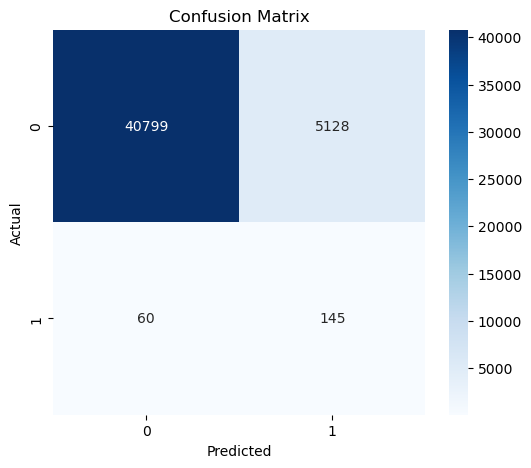

In [52]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

### Confusion Matrix Analysis

- True Positives (Killed correctly predicted)
- True Negatives (Injured correctly predicted)
- False Positives
- False Negatives

Special attention should be given to False Negatives because
predicting a fatal accident as non-fatal is a more serious error.

In [53]:
results = X_test.copy()
results['Actual'] = y_test.values
results['Predicted'] = y_pred

In [54]:
false_positive = results[
    (results['Actual'] == 0) &
    (results['Predicted'] == 1)
]
false_positive.head()

,CRASH_DATE,CRASH_TIME,PERSON_TYPE,PERSON_AGE,EJECTION,EMOTIONAL_STATUS,BODILY_INJURY,POSITION_IN_VEHICLE,SAFETY_EQUIPMENT,PED_LOCATION,PED_ACTION,COMPLAINT,PED_ROLE,CONTRIBUTING_FACTOR_1,CONTRIBUTING_FACTOR_2,PERSON_SEX,Actual,Predicted
209783,12/23/2013,12:40,Pedestrian,32.0,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,0,1
26912,07/04/2012,6:30,Pedestrian,30.0,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,0,1
224207,10/13/2017,20:09,Pedestrian,34.0,nan,Conscious,Head,nan,nan,Pedestrian/Bicyclist/Other Pedestrian Not at I...,Other Actions in Roadway,Complaint of Pain,Pedestrian,Pedestrian/Bicyclist/Other Pedestrian Error/Co...,Pedestrian/Bicyclist/Other Pedestrian Error/Co...,M,0,1
19300,09/21/2015,14:40,Occupant,77.0,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,0,1
13598,12/02/2014,13:30,Pedestrian,17.0,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,0,1


In [55]:
print("False Positives :", len(false_positive))

False Positives : 5128


In [56]:
false_negative = results[
    (results['Actual'] == 1) &
    (results['Predicted'] == 0)
]
false_negative.head()

,CRASH_DATE,CRASH_TIME,PERSON_TYPE,PERSON_AGE,EJECTION,EMOTIONAL_STATUS,BODILY_INJURY,POSITION_IN_VEHICLE,SAFETY_EQUIPMENT,PED_LOCATION,PED_ACTION,COMPLAINT,PED_ROLE,CONTRIBUTING_FACTOR_1,CONTRIBUTING_FACTOR_2,PERSON_SEX,Actual,Predicted
55298,12/03/2013,8:45,Occupant,49.0,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,1,0
210523,09/23/2015,19:05,Occupant,38.0,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,1,0
184450,03/20/2013,16:04,Occupant,23.0,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,1,0
117290,05/24/2015,5:40,Occupant,24.0,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,1,0
114870,09/13/2012,6:05,Occupant,35.0,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,1,0


In [57]:
print("False Negatives :", len(false_negative))

False Negatives : 60


### Error Analysis

False Negative cases are more critical because
the model failed to identify fatal injury cases.

These records should be inspected to understand
which factors contribute to incorrect predictions.

In [58]:
rf_model = best_model.named_steps['classifier']

In [59]:
feature_names = best_model.named_steps[
    'preprocessor'
].get_feature_names_out()

In [60]:
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
})
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

In [61]:
top15 = importance_df.head(15)

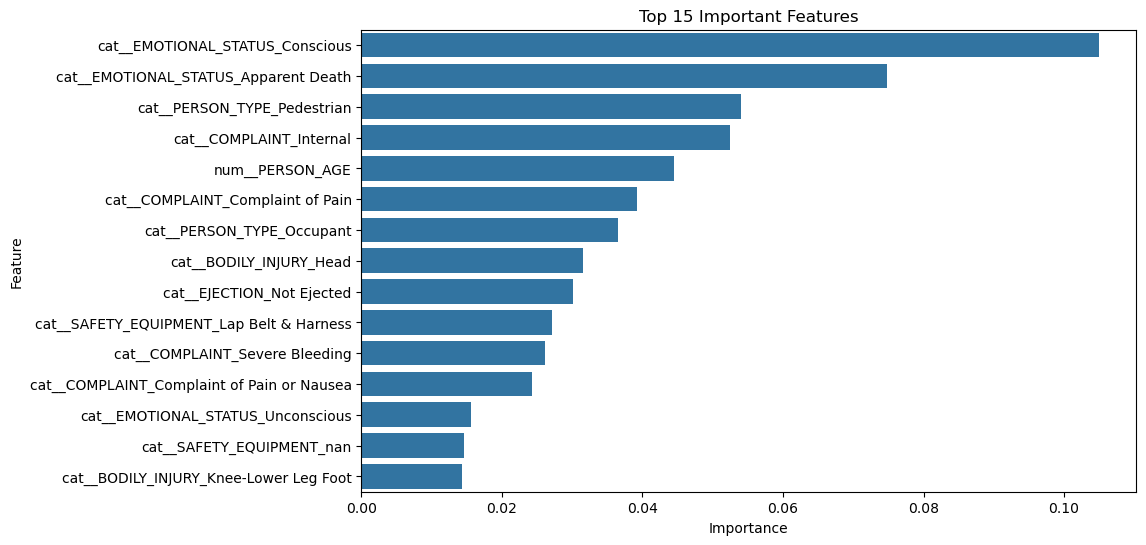

In [62]:
plt.figure(figsize=(10,6))
sns.barplot(
    data=top15,
    x='Importance',
    y='Feature'
)
plt.title("Top 15 Important Features")
plt.show()

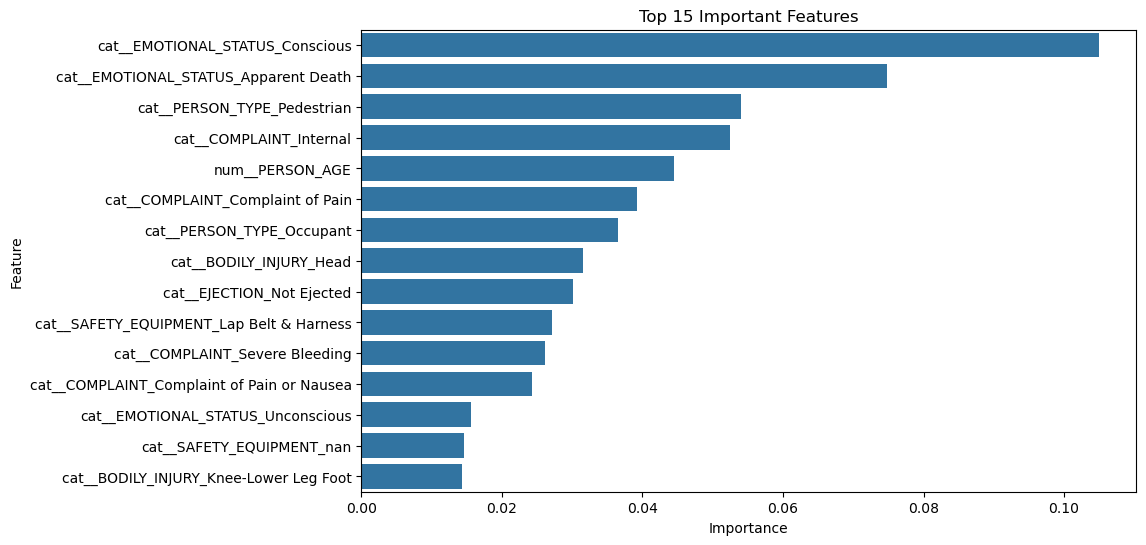

In [63]:
plt.figure(figsize=(10,6))
sns.barplot(
    data=top15,
    x='Importance',
    y='Feature'
)

plt.title("Top 15 Important Features")
plt.show()

In [64]:
y_prob = best_model.predict_proba(X_test)[:,1]

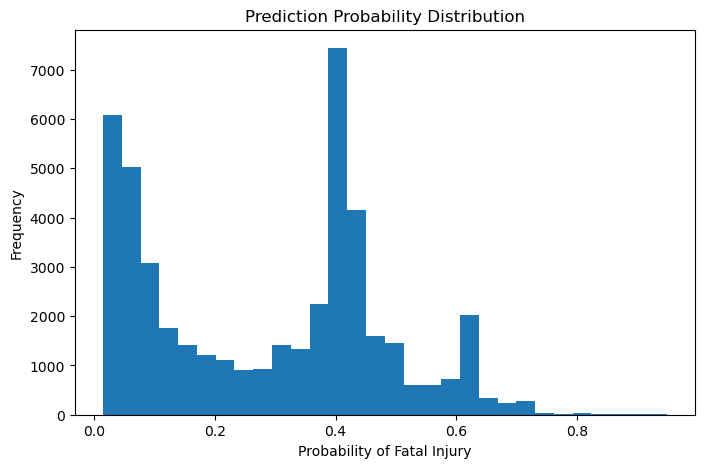

In [65]:
plt.figure(figsize=(8,5))
plt.hist(
    y_prob,
    bins=30
)
plt.title("Prediction Probability Distribution")
plt.xlabel("Probability of Fatal Injury")
plt.ylabel("Frequency")
plt.show()

### Probability Analysis

The distribution of prediction probabilities helps
understand model confidence and threshold behavior.

## Error Analysis and Explainability Summary

- Evaluated model using confusion matrix.
- Analyzed false positive and false negative cases.
- Identified most important predictive features.
- Examined prediction probability distribution.
- Improved interpretability of the Random Forest model.